# Grupa C – bias i reprezentatywność

Waszym zadaniem jest porównać próbkę 2000 rekordów z szerszym zbiorem referencyjnym UCI.

Przeczytaj również `readme/README_GRUPA_C.md`.

In [ ]:
!git clone https://github.com/poochacz/Podstawy_technologii_ML.git /content/eda_bank_marketing_colab

In [1]:
# Jednorazowe uruchomienie w Colabie:
# Jeśli pakiet został już rozpakowany w /content/eda_bank_marketing_colab,
# ta komórka tylko ustawi ścieżkę importów.
import sys
from pathlib import Path

COLAB_ROOT = Path("/content/eda_bank_marketing_colab/01_eda_bank_marketing_colab")
current = Path.cwd().resolve()
candidates = [COLAB_ROOT]
for directory in (current, *current.parents):
    candidates.extend((directory / "01_eda_bank_marketing_colab", directory))

ROOT = next(
    (candidate.resolve() for candidate in candidates if (candidate / "scripts").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Nie znaleziono katalogu projektu. Otwórz workspace zawierający "
        "01_eda_bank_marketing_colab albo uruchom notebook w Colabie."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "data"
print("Środowisko gotowe:", ROOT)

Środowisko gotowe: C:\Users\dariu\Documents\Studia Kato\Koźmiński\podstawy ML\podstawy_ML_repo\Podstawy_technologii_ML\01_eda_bank_marketing_colab


In [2]:
from scripts.data_setup import prepare_workshop_data

df, reference = prepare_workshop_data(
    data_dir=DATA_DIR,
    n=2000,
    random_state=42
)

print("Próbka:", df.shape)
print("Zbiór referencyjny:", reference.shape)

Próbka: (2000, 10)
Zbiór referencyjny: (41188, 10)


## Zakres danych warsztatowych

Zbiór warsztatowy zawiera wybrane kolumny z oryginalnego pliku UCI. Sprawdźcie, które informacje zostały uwzględnione, a które pominięte. Pominięcie jest decyzją o zakresie ćwiczenia, nie dowodem, że tych informacji nie ma w danych źródłowych.

In [3]:
import json
from scripts.group_c import compare_column_coverage

with (DATA_DIR / "workshop_metadata.json").open(encoding="utf-8") as metadata_file:
    metadata = json.load(metadata_file)

pokrycie_kolumn = compare_column_coverage(
    source_columns=metadata["source_columns"],
    workshop_columns=df.columns.tolist(),
)
pokrycie_kolumn

Zachowano 10 z 21 kolumn źródłowych.


,kolumna źródłowa,w zestawie warsztatowym,status
0,euribor3m,False,pominięta
1,marital,False,pominięta
2,cons.conf.idx,False,pominięta
3,default,False,pominięta
4,cons.price.idx,False,pominięta
5,loan,False,pominięta
6,emp.var.rate,False,pominięta
7,poutcome,False,pominięta
8,day_of_week,False,pominięta
9,nr.employed,False,pominięta


,kolumna źródłowa,w zestawie warsztatowym,status
0,euribor3m,False,pominięta
1,marital,False,pominięta
2,cons.conf.idx,False,pominięta
3,default,False,pominięta
4,cons.price.idx,False,pominięta
5,loan,False,pominięta
6,emp.var.rate,False,pominięta
7,poutcome,False,pominięta
8,day_of_week,False,pominięta
9,nr.employed,False,pominięta


## 1. Miesiąc kontaktu

,próbka_2000,pełny_zbiór,różnica_pp
month,,,
may,0.4905,0.3343,15.6204
jun,0.0765,0.1291,-5.2615
jul,0.1350,0.1742,-3.9177
aug,0.1225,0.1500,-2.7495
nov,0.0800,0.0996,-1.9568
oct,0.0065,0.0174,-1.0932
mar,0.0050,0.0133,-0.8256
sep,0.0075,0.0138,-0.6339
<NaN>,0.0040,0.0000,0.4000


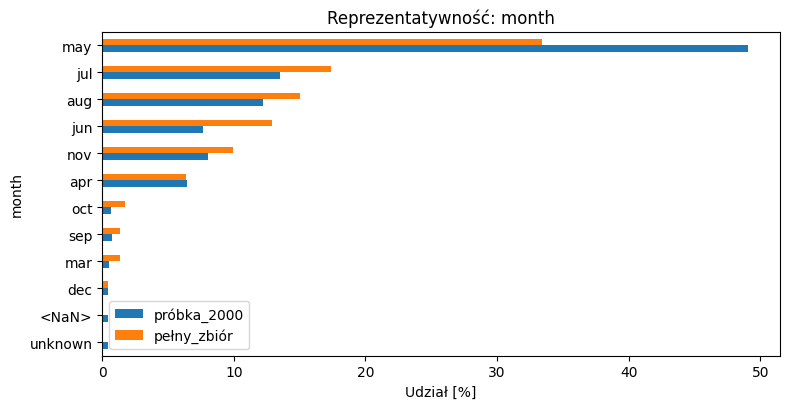

,próbka_2000,pełny_zbiór,różnica_pp
month,,,
may,0.4905,0.334296,15.620360
jun,0.0765,0.129115,-5.261528
jul,0.1350,0.174177,-3.917694
aug,0.1225,0.149995,-2.749514
nov,0.0800,0.099568,-1.956784
oct,0.0065,0.017432,-1.093226
mar,0.0050,0.013256,-0.825629
sep,0.0075,0.013839,-0.633898
<NaN>,0.0040,0.000000,0.400000


In [4]:
from scripts.group_c import compare_category

compare_category(df, reference, "month")

## 2. Kanał kontaktu

,próbka_2000,pełny_zbiór,różnica_pp
contact,,,
cellular,0.652,0.6347,1.7252
telephone,0.348,0.3653,-1.7252


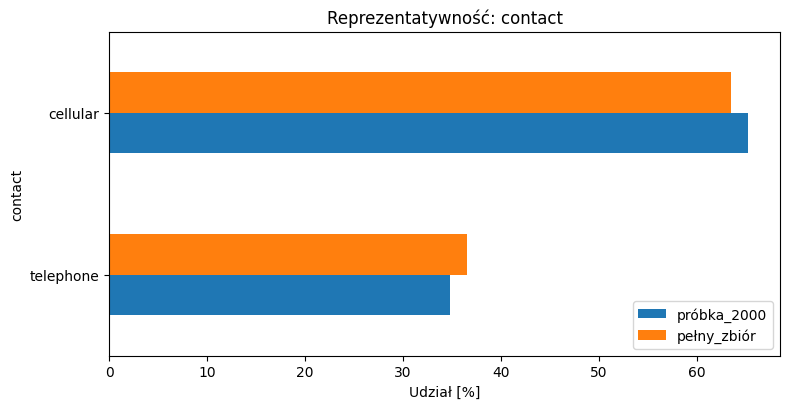

,próbka_2000,pełny_zbiór,różnica_pp
contact,,,
cellular,0.652,0.634748,1.725202
telephone,0.348,0.365252,-1.725202


In [6]:
compare_category(df, reference, "contact")

## 3. Zawód

,próbka_2000,pełny_zbiór,różnica_pp
job,,,
blue-collar,0.2585,0.2247,3.3823
services,0.1170,0.0964,2.0637
retired,0.0290,0.0418,-1.2760
admin.,0.2420,0.2530,-1.1035
management,0.0600,0.0710,-1.0992
housemaid,0.0150,0.0257,-1.0736
technician,0.1560,0.1637,-0.7713
unemployed,0.0225,0.0246,-0.2119
self-employed,0.0330,0.0345,-0.1500


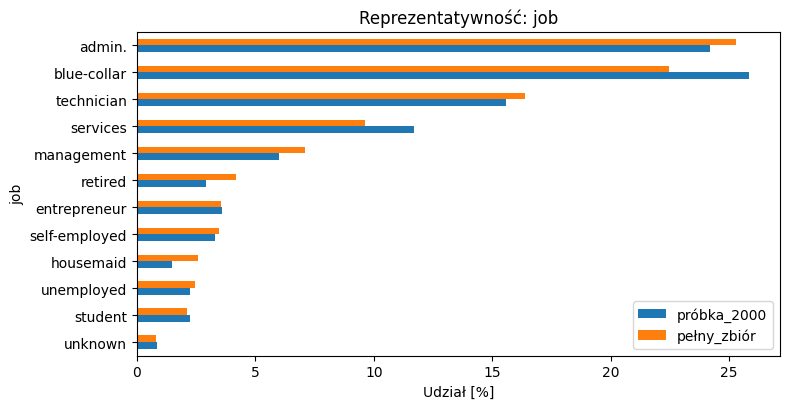

,próbka_2000,pełny_zbiór,różnica_pp
job,,,
blue-collar,0.2585,0.224677,3.382291
services,0.1170,0.096363,2.063698
retired,0.0290,0.041760,-1.275974
admin.,0.2420,0.253035,-1.103486
management,0.0600,0.070992,-1.099155
housemaid,0.0150,0.025736,-1.073565
technician,0.1560,0.163713,-0.771273
unemployed,0.0225,0.024619,-0.211882
self-employed,0.0330,0.034500,-0.150034


In [7]:
compare_category(df, reference, "job")

## 4. Struktura wieku

,próbka_2000,pełny_zbiór,różnica_pp
age,,,
<30,0.1470,0.1376,0.9333
30–39,0.3990,0.4112,-1.2246
40–49,0.2768,0.2556,2.1208
50–59,0.1571,0.1666,-0.9531
60–69,0.0136,0.0176,-0.3942
70+,0.0066,0.0114,-0.4821


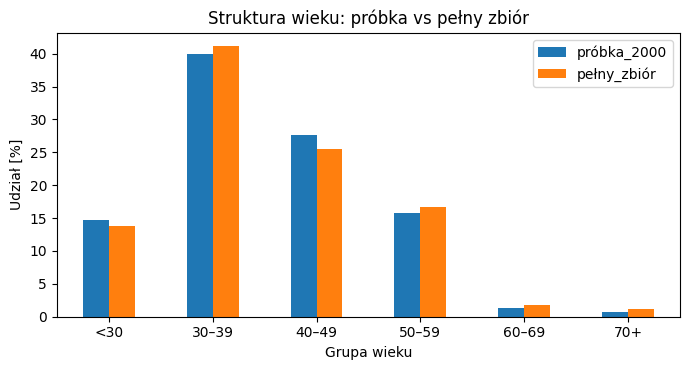

,próbka_2000,pełny_zbiór,różnica_pp
age,,,
<30,0.146970,0.137637,0.933252
30–39,0.398990,0.411236,-1.224638
40–49,0.276768,0.255560,2.120780
50–59,0.157071,0.166602,-0.953122
60–69,0.013636,0.017578,-0.394157
70+,0.006566,0.011387,-0.482116


In [10]:
from scripts.group_c import compare_age

compare_age(df, reference)

## 5. Czy zmienił się również target?

In [8]:
from scripts.group_c import compare_target

compare_target(df, reference)

,próbka_2000,pełny_zbiór,różnica_pp
y,,,
no,0.8895,0.8873,0.2154
yes,0.1105,0.1127,-0.2154


,próbka_2000,pełny_zbiór,różnica_pp
y,,,
no,0.8895,0.887346,0.215417
yes,0.1105,0.112654,-0.215417


## 6. Największe różnice

In [9]:
from scripts.group_c import largest_gaps

largest_gaps(df, reference)

,kolumna,kategoria,próbka,pełny_zbiór,różnica_pp
7,month,may,0.4905,0.3343,15.6204
5,month,jun,0.0765,0.1291,-5.2615
4,month,jul,0.1350,0.1742,-3.9177
15,job,blue-collar,0.2585,0.2247,3.3823
2,month,aug,0.1225,0.1500,-2.7495
21,job,services,0.1170,0.0964,2.0637
8,month,nov,0.0800,0.0996,-1.9568
12,contact,cellular,0.6520,0.6347,1.7252
13,contact,telephone,0.3480,0.3653,-1.7252
19,job,retired,0.0290,0.0418,-1.2760


,kolumna,kategoria,próbka,pełny_zbiór,różnica_pp
7,month,may,0.4905,0.334296,15.620360
5,month,jun,0.0765,0.129115,-5.261528
4,month,jul,0.1350,0.174177,-3.917694
15,job,blue-collar,0.2585,0.224677,3.382291
2,month,aug,0.1225,0.149995,-2.749514
21,job,services,0.1170,0.096363,2.063698
8,month,nov,0.0800,0.099568,-1.956784
12,contact,cellular,0.6520,0.634748,1.725202
13,contact,telephone,0.3480,0.365252,-1.725202
19,job,retired,0.0290,0.041760,-1.275974


## 7. Czy próbce brakuje jakichś kategorii?

Ta tabela pokazuje kategorie obecne w pełnym zbiorze referencyjnym, których nie ma w próbce warsztatowej. Przy każdej widać, ilu klientów i jaki odsetek referencji reprezentuje; nawet mała pominięta grupa może być ważna biznesowo.

In [4]:
from scripts.group_c import categories_absent_from_sample

brakujace_kategorie = categories_absent_from_sample(df, reference)

Każda sprawdzana kategoria z referencji występuje w próbce.


### Symulacja: co jeśli usuniemy jedną kategorię?

Zmieńcie zawód lub inną kategorię w następnej komórce. Porównanie pokaże liczebność i odsetek lokat przed wykluczeniem, po usunięciu kategorii **z próbki** oraz w pełnej referencji. Referencja pozostaje bez zmian, żeby pokazać, czy wykluczenie oddala próbkę od szerszego zbioru.

In [3]:
from scripts.group_c import simulate_category_exclusion

# Wybierz kategorię, np. zawód "admin.".
CECHA_DO_WYKLUCZENIA = "job"
KATEGORIA_DO_WYKLUCZENIA = "admin."

wyniki_wykluczenia = simulate_category_exclusion(
    sample=df,
    reference=reference,
    column=CECHA_DO_WYKLUCZENIA,
    category=KATEGORIA_DO_WYKLUCZENIA,
)

Symulacja wykluczenia kategorii 'admin.' z próbki. Pełna referencja pozostaje bez zmian.


,wariant,liczba klientów,usunięte rekordy,brak lokaty,lokata,odsetek lokat (%),różnica do referencji (p.p.)
0,Próbka przed wykluczeniem,2000,0,1779,221,11.1,-0.2
1,Próbka bez job = admin.,1516,484,1373,143,9.4,-1.9
2,Pełna referencja,41188,0,36548,4640,11.3,0.0


## 8. Czy próbka zmienia obraz wyników w segmentach?

Porównujemy odsetek klientów, którzy założyli lokatę (`y = yes`), **w obrębie tej samej kategorii**. Dla każdego segmentu widać także liczebność próbki i referencji. Zwróćcie uwagę, czy wnioski o danym segmencie są podobne w obu zbiorach.

In [5]:
from scripts.group_c import compare_category_target_rates

porownanie_wynikow_segmentow = compare_category_target_rates(df, reference)

,zmienna,kategoria,klienci w próbce,lokaty w próbce,odsetek lokat w próbce (%),klienci w referencji,lokaty w referencji,odsetek lokat w referencji (%),różnica (p.p.)
0,month,mar,10,2,20.0,546,276,50.5,-30.5
1,month,sep,15,11,73.3,570,256,44.9,28.4
2,month,dec,8,5,62.5,182,89,48.9,13.6
3,month,apr,129,43,33.3,2632,539,20.5,12.9
4,month,oct,13,7,53.8,718,315,43.9,10.0
5,job,unemployed,45,3,6.7,1014,144,14.2,-7.5
6,job,student,45,11,24.4,875,275,31.4,-7.0
7,job,housemaid,30,5,16.7,1060,106,10.0,6.7
8,job,unknown,17,1,5.9,330,37,11.2,-5.3
9,job,management,120,8,6.7,2924,328,11.2,-4.6


## Przygotujcie 2–3 wnioski

1. Które kolumny źródłowe pominięto i czy któraś z nich mogłaby być ważna dla decyzji biznesowej?
2. Czy próbce brakuje jakichś kategorii? Czy to ważne grupy klientów?
3. W których kategoriach odsetek założonych lokat najbardziej różni się między próbką i referencją?
4. Co zmieniło wykluczenie wybranego zawodu lub kategorii? Czy po tej zmianie próbka lepiej, czy gorzej odzwierciedla referencję?
5. Jak pobralibyście lepszą próbkę?

**Uwaga:** pełny zbiór UCI również nie jest „całą populacją świata”. Jest tylko szerszym punktem odniesienia.